# Day 11: Introduction to ML in Computer Vision
Today we will cover:
- kNN (k-Nearest Neighbors)
- SVM (Support Vector Machines)

## Why ML in CV?
Machine Learning algorithms can classify and recognize patterns in images. kNN and SVM are classical ML methods that work well for tasks like digit recognition.

## kNN Classifier
kNN classifies a sample based on the majority label of its nearest neighbors.
- Pros: Simple, intuitive.
- Cons: Slow for large datasets.

## SVM Classifier
SVM finds a hyperplane that separates classes with maximum margin.
- Pros: Effective in high-dimensional spaces.
- Cons: Computationally expensive for large datasets.

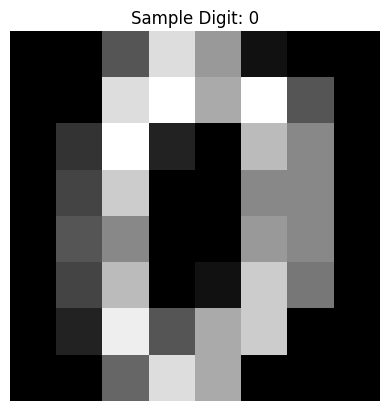

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn import datasets
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.metrics import classification_report, confusion_matrix

# Load MNIST digits dataset
digits = datasets.load_digits()
X = digits.images.reshape((len(digits.images), -1))
y = digits.target

# Split into train and test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# Show sample digit
plt.imshow(digits.images[0], cmap='gray')
plt.title(f"Sample Digit: {digits.target[0]}")
plt.axis('off')
plt.show()

## Exercise: Classify Digits with kNN

In [3]:
# Train kNN classifier
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train, y_train)
y_pred_knn = knn.predict(X_test)

print("kNN Classification Report:")
print(classification_report(y_test, y_pred_knn))

kNN Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        53
           1       1.00      1.00      1.00        50
           2       1.00      1.00      1.00        47
           3       0.98      1.00      0.99        54
           4       0.98      1.00      0.99        60
           5       0.98      0.98      0.98        66
           6       1.00      1.00      1.00        53
           7       1.00      1.00      1.00        55
           8       1.00      1.00      1.00        43
           9       0.98      0.95      0.97        59

    accuracy                           0.99       540
   macro avg       0.99      0.99      0.99       540
weighted avg       0.99      0.99      0.99       540



## Exercise: Classify Digits with SVM

In [4]:
# Train SVM classifier
svm = SVC(kernel='linear', gamma='scale')
svm.fit(X_train, y_train)
y_pred_svm = svm.predict(X_test)

print("SVM Classification Report:")
print(classification_report(y_test, y_pred_svm))

SVM Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        53
           1       0.98      0.98      0.98        50
           2       0.98      1.00      0.99        47
           3       1.00      0.96      0.98        54
           4       0.98      0.98      0.98        60
           5       0.97      0.97      0.97        66
           6       1.00      1.00      1.00        53
           7       0.96      0.98      0.97        55
           8       0.95      0.98      0.97        43
           9       0.97      0.95      0.96        59

    accuracy                           0.98       540
   macro avg       0.98      0.98      0.98       540
weighted avg       0.98      0.98      0.98       540



## Mini Project: Handwritten Digit Recognizer
We will build a simple recognizer that takes a digit image and predicts its label using the trained SVM model.

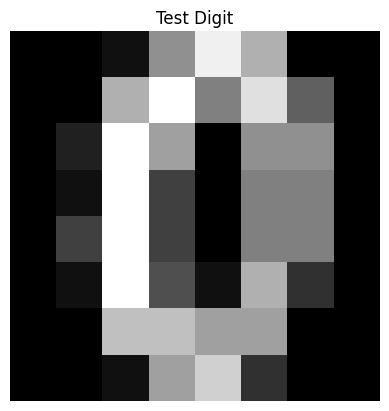

Predicted Label: 0


In [5]:
def recognize_digit(image):
    image = image.reshape(1, -1)
    prediction = svm.predict(image)
    return prediction[0]

# Test with a sample digit
sample_image = digits.images[10]
plt.imshow(sample_image, cmap='gray')
plt.title("Test Digit")
plt.axis('off')
plt.show()

print("Predicted Label:", recognize_digit(digits.images[10]))